# Q3: What mix of shooters and other roles works best in a lineup?

**Plan, fixed before looking at results.**

1. **Roles.** Take every player-season with at least 300 minutes, 2014-15 to 2025-26 (regular season). Features: 3PA rate (3PA/FGA), 3PA per 36, usage %, assist %, offensive and defensive rebound %, height, blocks per 36. Each feature is z-scored within its season so the league-wide rise in threes does not decide the roles. Cluster with k-means across all seasons; k is chosen from 4 to 8 by silhouette score.
2. **Lineups.** All five-man units with at least 20 minutes together, regular season. Keep a lineup only if all five players have a role.
3. **Model.** Net rating regressed on the number of players of each role in the lineup (the five counts sum to 5, so one role is the reference), weighted by possessions, with team-season fixed effects (so we compare a team's lineups with each other) and errors clustered by team-season. Diminishing returns: add the square of the count for the main shooter role.
4. **Robustness.** Replace clusters with a simple count of players whose 3PA rate is at least 50%.

Limits stated up front: lineup net rating is noisy and role mix is confounded with player quality (good players tend to be a certain role), so this describes associations, not causal effects of roster construction.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
RAW = Path('..') / 'data' / 'raw' / 'roles'
SEASONS = [f'{y}-{str(y + 1)[-2:]}' for y in range(2014, 2026)]
plt.rcParams['figure.dpi'] = 110

def load_players(s):
    b = pd.read_parquet(RAW / f'players_base_{s}.parquet')[['PLAYER_ID', 'PLAYER_NAME', 'MIN', 'FGA', 'FG3A', 'BLK']]
    a = pd.read_parquet(RAW / f'players_adv_{s}.parquet')[['PLAYER_ID', 'USG_PCT', 'AST_PCT', 'OREB_PCT', 'DREB_PCT']]
    h = pd.read_parquet(RAW / f'bio_{s}.parquet')[['PLAYER_ID', 'PLAYER_HEIGHT_INCHES']]
    d = b.merge(a, on='PLAYER_ID').merge(h, on='PLAYER_ID', how='left')
    d['SEASON'] = s
    return d
P = pd.concat([load_players(s) for s in SEASONS], ignore_index=True)
print(len(P), 'player-seasons;', (P.MIN >= 300).sum(), 'with >= 300 min')
P = P[P.MIN >= 300].copy()
P['FG3A_RATE'] = P.FG3A / P.FGA.replace(0, np.nan)
P['FG3A_36'] = P.FG3A / P.MIN * 36
P['BLK_36'] = P.BLK / P.MIN * 36
P['HEIGHT'] = P.PLAYER_HEIGHT_INCHES
feats = ['FG3A_RATE', 'FG3A_36', 'USG_PCT', 'AST_PCT', 'OREB_PCT', 'DREB_PCT', 'HEIGHT', 'BLK_36']
P = P.dropna(subset=feats).copy()
Z = P.groupby('SEASON')[feats].transform(lambda x: (x - x.mean()) / x.std())
print(len(P), 'player-seasons clustered')

6460 player-seasons; 4871 with >= 300 min
4871 player-seasons clustered


In [2]:
sil = {}
for k in range(4, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z)
    sil[k] = silhouette_score(Z, km.labels_, sample_size=3000, random_state=0)
print({k: round(v, 3) for k, v in sil.items()})
K = max(sil, key=sil.get); print('chosen k =', K)
km = KMeans(n_clusters=K, n_init=20, random_state=0).fit(Z)
P['CLUSTER'] = km.labels_
prof = P.groupby('CLUSTER')[feats].mean().round(2); prof['players'] = P.groupby('CLUSTER').size()
prof['example'] = P.sort_values('MIN', ascending=False).groupby('CLUSTER').PLAYER_NAME.apply(lambda x: ', '.join(x.drop_duplicates().head(4)))
prof

{4: 0.214, 5: 0.207, 6: 0.196, 7: 0.184, 8: 0.179}
chosen k = 4


,FG3A_RATE,FG3A_36,USG_PCT,AST_PCT,OREB_PCT,DREB_PCT,HEIGHT,BLK_36,players,example
CLUSTER,,,,,,,,,,
0,0.08,1.08,0.18,0.10,0.10,0.20,82.59,1.60,990,"Karl-Anthony Towns, Domantas Sabonis, Giannis ..."
1,0.37,4.33,0.17,0.11,0.05,0.15,80.01,0.77,1345,"Andrew Wiggins, Mikal Bridges, Amen Thompson, ..."
2,0.36,5.50,0.23,0.26,0.02,0.11,75.46,0.38,1132,"James Harden, Andrew Wiggins, Bradley Beal, Le..."
3,0.57,6.56,0.16,0.11,0.02,0.10,77.29,0.41,1404,"Mikal Bridges, Trevor Ariza, Paul George, P.J...."


Names for the clusters are assigned by reading the table above (done after seeing it, so they are descriptive labels only; the analysis does not depend on the names).

In [3]:
NAMES = {}   # filled in by the next step from the profile
# label from the profile: shooter = highest 3PA rate (among clusters), big = tallest, creator = highest usage/assist
prof2 = P.groupby('CLUSTER')[feats].mean()
NAMES[prof2.FG3A_RATE.idxmax()] = 'shooter'
rest = prof2.drop(index=list(NAMES))
NAMES[rest.HEIGHT.idxmax()] = 'big'
rest = prof2.drop(index=list(NAMES))
NAMES[rest.AST_PCT.idxmax()] = 'creator'
for c in prof2.index:
    NAMES.setdefault(c, f'other{c}')
P['ROLE'] = P.CLUSTER.map(NAMES)
print(NAMES)
P.groupby('ROLE').size()

{np.int32(3): 'shooter', np.int32(0): 'big', np.int32(2): 'creator', 1: 'other1'}


ROLE
big         990
creator    1132
other1     1345
shooter    1404
dtype: int64

## Lineups

In [4]:
frames = []
for s in SEASONS:
    for f in sorted(RAW.glob(f'lineups_adv_{s}_*.parquet')):
        x = pd.read_parquet(f); x['SEASON'] = s; frames.append(x)
L = pd.concat(frames, ignore_index=True)
print(len(L), 'five-man lineups (all minutes);', (L.MIN >= 20).sum(), 'with >= 20 min')
L = L[L.MIN >= 20].copy()
role_of = P.set_index(['SEASON', 'PLAYER_ID']).ROLE.to_dict()
hi3 = (P.set_index(['SEASON', 'PLAYER_ID']).FG3A_RATE >= .5).astype(int).to_dict()
def parse(r):
    ids = [int(i) for i in r.GROUP_ID.strip('-').split('-')]
    return [role_of.get((r.SEASON, i)) for i in ids], [hi3.get((r.SEASON, i)) for i in ids]
pr = L.apply(parse, axis=1)
L['roles'] = [x[0] for x in pr]; L['hi3'] = [x[1] for x in pr]
ok = L.roles.apply(lambda r: all(v is not None for v in r))
print(f'kept {ok.sum()} of {len(L)} lineups where all five players have a role')
L = L[ok].copy()
for r in sorted(set(NAMES.values())):
    L[f'n_{r}'] = L.roles.apply(lambda x: sum(v == r for v in x))
L['n_hi3'] = L.hi3.apply(sum)
L['TEAM_SEASON'] = L.TEAM_ABBREVIATION + '_' + L.SEASON
L = L.dropna(subset=['NET_RATING', 'POSS'])
print(L[[c for c in L.columns if c.startswith('n_')]].apply(lambda s: s.value_counts()).fillna(0).astype(int))

185228 five-man lineups (all minutes); 12953 with >= 20 min


kept 12498 of 12953 lineups where all five players have a role
   n_big  n_creator  n_other1  n_shooter  n_hi3
0   2001        970      2442       1812   2929
1   8844       6281      5301       5509   4745
2   1644       4662      3636       4183   3543
3      9        569      1009        938   1114
4      0         16       109         55    157
5      0          0         1          1     10


In [5]:
roles = sorted(set(NAMES.values()))
ref = 'creator' if 'creator' in roles else roles[0]
others = [r for r in roles if r != ref and r != 'shooter']
def fit(f, data=L):
    return smf.wls(f, data=data, weights=data.POSS).fit(cov_type='cluster', cov_kwds={'groups': data.TEAM_SEASON})
terms = ' + '.join(f'n_{r}' for r in roles if r != ref)
m1 = fit(f'NET_RATING ~ {terms} + C(TEAM_SEASON)')
m2 = fit(f'NET_RATING ~ {terms} + I(n_shooter**2) + C(TEAM_SEASON)')
print(f'Reference role: {ref}. Coefficient = change in lineup net rating from swapping one {ref} for that role.')
tab = pd.DataFrame({'coef': m1.params, 'se': m1.bse, 'p': m1.pvalues}).filter(regex='^n_', axis=0)
display(tab.round(3))
q = pd.DataFrame({'coef': m2.params, 'se': m2.bse, 'p': m2.pvalues}).filter(regex='n_shooter', axis=0)
print('With a squared shooter term (diminishing returns if the squared coefficient is negative):'); display(q.round(4))

Reference role: creator. Coefficient = change in lineup net rating from swapping one creator for that role.


,coef,se,p
n_big,-0.844,0.518,0.103
n_other1,-1.287,0.381,0.001
n_shooter,-0.714,0.345,0.038


With a squared shooter term (diminishing returns if the squared coefficient is negative):


,coef,se,p
n_shooter,-1.3351,0.6238,0.0323
I(n_shooter ** 2),0.2218,0.1884,0.2391


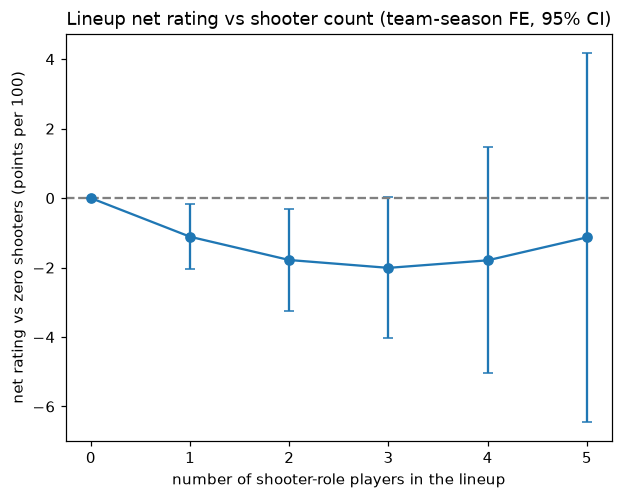

Lineups by shooter count: {0: 1812, 1: 5509, 2: 4183, 3: 938, 4: 55, 5: 1}


In [6]:
b1, b2 = m2.params['n_shooter'], m2.params['I(n_shooter ** 2)']
se = m2.cov_params().loc[['n_shooter', 'I(n_shooter ** 2)']].loc[:, ['n_shooter', 'I(n_shooter ** 2)']]
xs = np.arange(0, 6)
eff = b1 * xs + b2 * xs**2
cov = se.values
sd = np.sqrt([np.array([x, x**2]) @ cov @ np.array([x, x**2]) for x in xs])
plt.errorbar(xs, eff, yerr=1.96 * sd, fmt='o-', capsize=3)
plt.axhline(0, c='gray', ls='--'); plt.xlabel('number of shooter-role players in the lineup')
plt.ylabel('net rating vs zero shooters (points per 100)'); plt.title('Lineup net rating vs shooter count (team-season FE, 95% CI)')
plt.show()
print('Lineups by shooter count:', L.n_shooter.value_counts().sort_index().to_dict())

In [7]:
# Robustness: simple count of players with 3PA rate >= 50%
r1 = fit('NET_RATING ~ n_hi3 + I(n_hi3**2) + C(TEAM_SEASON)')
print(r1.params.filter(regex='n_hi3').round(3).to_dict(), r1.pvalues.filter(regex='n_hi3').round(3).to_dict())
print('Lineups by n_hi3:', L.n_hi3.value_counts().sort_index().to_dict())
# by era, linear shooter count effect
L['ERA'] = pd.cut(L.SEASON.str[:4].astype(int), [2013, 2017, 2021, 2025], labels=['2014-18', '2018-22', '2022-26'])
for era, d in L.groupby('ERA', observed=True):
    mm = fit(f'NET_RATING ~ {terms} + C(TEAM_SEASON)', d)
    print(era, 'shooter coef %.2f (se %.2f), n=%d' % (mm.params['n_shooter'], mm.bse['n_shooter'], len(d)))

{'n_hi3': 0.887, 'I(n_hi3 ** 2)': 0.074} {'n_hi3': 0.106, 'I(n_hi3 ** 2)': 0.67}
Lineups by n_hi3: {0: 2929, 1: 4745, 2: 3543, 3: 1114, 4: 157, 5: 10}


2014-18 shooter coef -1.19 (se 0.61), n=4426


2018-22 shooter coef -1.18 (se 0.58), n=3963


2022-26 shooter coef 0.11 (se 0.58), n=4109
